
CS505 – Data Mining
## Assignment 1: From Raw Data to Insights
### Student: Matheus Dornelles and Mathieu Lavoie

**AI tools acknowledgment:** This notebook was prepared with Co-pilot drafting for structure and code; the final analysis, interpretation, and reporting were reviewed and adapted by the student.

## Part A – Problem Framing

**A.1 Goal**
We want to understand which passenger characteristics were associated with survival on the Titanic. The goal is to estimate whether factors such as sex, age, class, fare, and embarkation location help explain who was more likely to survive.

**A.2 CRISP-DM Mapping**
- Business understanding: Define the research question and decide that survival prediction is the practical task.
- Data understanding: Inspect variables, missingness, and distributions in the Titanic dataset.
- Data preparation: Handle missing values, encode categories, clip extreme outliers, and create a clean analysis table.
- Modeling: Build a predictive model or a feature-based analysis to relate passenger attributes to survival.
- Evaluation: Assess predictive performance and the strength of relationships between key features and the target.
- Deployment: Use the findings to explain survival patterns and to motivate future feature engineering or model-building decisions.

**A.3 Task Type**
The main task is classification. The target variable is `survived`, which is binary and indicates whether a passenger survived the disaster. A classification model is appropriate because we want to predict a categorical outcome from multiple explanatory variables.

**A.4 Ethical Considerations**
- Historical bias: The dataset reflects a historical disaster in which social class and gender strongly shaped access to safety; using it without context may reinforce stereotypes rather than capture the real causal mechanisms.
- Fairness and sensitive attributes: Sex and class are highly predictive, but using them in a naive model may create unfair or ethically problematic decisions if the model is applied beyond historical context.
- Privacy and representation: Even though the dataset is historical, passenger records can still encode sensitive identity information; interpretation should avoid reducing people to a single summary label or making normative judgments from a limited snapshot.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = sns.load_dataset("titanic")
print("Shape:", df.shape)
print("Dtypes:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum().sort_values(ascending=False))
df.head()

Shape: (891, 15)
Dtypes:
survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object

Missing values per column:
deck           688
age            177
embarked         2
embark_town      2
sex              0
pclass           0
survived         0
fare             0
parch            0
sibsp            0
class            0
adult_male       0
who              0
alive            0
alone            0
dtype: int64


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Part B – Data Understanding & Preprocessing

### B.1 Data-quality assessment
The raw Titanic dataset has several common problems for analysis: missing values in `age`, `deck`, and `embarked`; categorical features stored as strings; a few extreme `fare` values; and some redundant or weak features such as `cabin`, `ticket`, and `name`. The target variable `survived` is binary and does not have missing values.

In [21]:
# Missing value profile
missing = df.isna().sum().sort_values(ascending=False)
print("Missing values (% of column):")
print((missing / len(df) * 100).round(2))

# Basic statistics for numeric variables
print("\nNumeric summary:")
print(df.describe().round(2))

# Value counts for categorical variables of interest
for col in ["sex", "embarked", "class", "who", "survived"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

# Check obvious outliers manually
for col in ["age", "fare"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    print(f"{col}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, lower={lower:.2f}, upper={upper:.2f}")
    print(df[col][(df[col] < lower) | (df[col] > upper)].head())

Missing values (% of column):
deck           77.22
age            19.87
embarked        0.22
embark_town     0.22
sex             0.00
pclass          0.00
survived        0.00
fare            0.00
parch           0.00
sibsp           0.00
class           0.00
adult_male      0.00
who             0.00
alive           0.00
alone           0.00
dtype: float64

Numeric summary:
       survived  pclass     age   sibsp   parch    fare
count    891.00  891.00  714.00  891.00  891.00  891.00
mean       0.38    2.31   29.70    0.52    0.38   32.20
std        0.49    0.84   14.53    1.10    0.81   49.69
min        0.00    1.00    0.42    0.00    0.00    0.00
25%        0.00    2.00   20.12    0.00    0.00    7.91
50%        0.00    3.00   28.00    0.00    0.00   14.45
75%        1.00    3.00   38.00    1.00    0.00   31.00
max        1.00    3.00   80.00    8.00    6.00  512.33

--- sex ---
sex
male      577
female    314
Name: count, dtype: int64

--- embarked ---
embarked
S      644
C      16

**Summary of data-quality issues:**
- `age` has about 20% missing values, so it must be treated carefully because it is a key predictor.
- `embarked` has a small number of missing values, which can be filled with the most common port without distorting the pattern too much.
- `deck` and `cabin` are mostly missing, so they are weak features for modeling and are better handled by creating a simpler indicator or dropping them.
- `fare` has a right-skewed distribution and a few unusually high values, which should be clipped or winsorized to reduce the effect of extreme outliers.
- Some columns such as `sex`, `class`, and `embarked` are categorical and must be encoded before modeling.

### B.2 Preprocessing decisions and implementation

**Missing values:** Age is important and not random, so we fill missing ages using the median within sex and passenger class groups. This preserves the age distribution better than using a single global median. `embarked` values are filled with the mode, because there are only two missing entries and the most common embarkation port is the least disruptive choice.

**Outliers:** `fare` is right-skewed with some extreme values, so we clip values above the upper 1.5×IQR boundary. This reduces the leverage of a few very expensive tickets without dropping the rows entirely.

**Encoding:** We convert categorical variables to dummy variables, using `drop_first=True` to avoid perfect multicollinearity and keep the model matrix compact.

**Scaling:** Numerical features (`age`, `fare`, `sibsp`, `parch`) are standardized using z-scores so that variables on different scales contribute fairly during modeling.

In [22]:
# Work on a copy
df_clean = df.copy()

# Missing values
df_clean['age'] = df_clean.groupby(['sex', 'pclass'])['age'].transform(
    lambda s: s.fillna(s.median())
)
df_clean['embarked'] = df_clean['embarked'].fillna(df_clean['embarked'].mode()[0])
if 'cabin' in df_clean.columns:
    df_clean['cabin_present'] = df_clean['cabin'].notna().astype(int)
else:
    df_clean['cabin_present'] = 0
for col in ['cabin', 'deck', 'ticket', 'name']:
    if col in df_clean.columns:
        df_clean = df_clean.drop(columns=[col])

# Outliers (fare only; age retained but can also be clipped if needed)
q1 = df_clean['fare'].quantile(0.25)
q3 = df_clean['fare'].quantile(0.75)
iqr = q3 - q1
lower_fare = q1 - 1.5 * iqr
upper_fare = q3 + 1.5 * iqr
df_clean['fare'] = df_clean['fare'].clip(lower=lower_fare, upper=upper_fare)

# Encode categorical variables
categorical_cols = ['sex', 'embarked', 'class', 'who', 'embark_town']
for col in categorical_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(str)

# Convert bools to numeric to simplify modeling
for col in ['adult_male', 'alone']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(int)

df_model = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

# Scale numeric features
numeric_cols = ['age', 'fare', 'sibsp', 'parch']
for col in numeric_cols:
    if col in df_model.columns:
        df_model[col] = (df_model[col] - df_model[col].mean()) / df_model[col].std(ddof=0)

df_model.head()

,survived,pclass,age,sibsp,parch,fare,adult_male,alive,alone,cabin_present,sex_male,embarked_Q,embarked_S,class_Second,class_Third,who_man,who_woman,embark_town_Queenstown,embark_town_Southampton
0,0,3,-0.534891,0.432793,-0.473674,-0.820552,1,no,0,0,True,False,True,False,True,True,False,False,True
1,1,1,0.668392,0.432793,-0.473674,2.031623,0,yes,0,0,False,False,False,False,False,False,True,False,False
2,1,3,-0.234070,-0.474545,-0.473674,-0.787578,0,yes,1,0,False,False,True,False,True,False,True,False,True
3,1,1,0.442776,0.432793,-0.473674,1.419297,0,yes,0,0,False,False,True,False,False,False,True,False,True
4,0,3,0.442776,-0.474545,-0.473674,-0.781471,1,no,1,0,True,False,True,False,True,True,False,False,True


### B.3 Reproducible pipeline
The steps are organized in a reproducible function so the raw dataset can be turned into a clean analysis table with one call. This makes it easy to re-run the preprocessing and guarantees the same transformation logic each time.

In [23]:
def preprocess_titanic(raw_df):
    df_proc = raw_df.copy()
   
    # Missing data
    df_proc['age'] = df_proc.groupby(['sex', 'pclass'])['age'].transform(
        lambda s: s.fillna(s.median())
    )
    df_proc['embarked'] = df_proc['embarked'].fillna(df_proc['embarked'].mode()[0])
    if 'cabin' in df_proc.columns:
        df_proc['cabin_present'] = df_proc['cabin'].notna().astype(int)
    else:
        df_proc['cabin_present'] = 0
    for col in ['cabin', 'deck', 'ticket', 'name']:
        if col in df_proc.columns:
            df_proc = df_proc.drop(columns=[col])

    # Outlier handling
    q1 = df_proc['fare'].quantile(0.25)
    q3 = df_proc['fare'].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df_proc['fare'] = df_proc['fare'].clip(lower=lower, upper=upper)

    # Encoding
    for col in ['sex', 'embarked', 'class', 'who', 'embark_town']:
        if col in df_proc.columns:
            df_proc[col] = df_proc[col].astype(str)
    for col in ['adult_male', 'alone']:
        if col in df_proc.columns:
            df_proc[col] = df_proc[col].astype(int)
    df_proc = pd.get_dummies(df_proc, columns=['sex', 'embarked', 'class', 'who', 'embark_town'], drop_first=True)

    # Scaling
    numeric_cols = ['age', 'fare', 'sibsp', 'parch']
    for col in numeric_cols:
        if col in df_proc.columns:
            df_proc[col] = (df_proc[col] - df_proc[col].mean()) / df_proc[col].std(ddof=0)

    return df_proc

# Run the reusable preprocessing function
df_clean = preprocess_titanic(df)
print("Cleaned shape:", df_clean.shape)
print("Missing values after cleaning:", df_clean.isna().sum().sum())
df_clean.head()

Cleaned shape: (891, 19)
Missing values after cleaning: 0


,survived,pclass,age,sibsp,parch,fare,adult_male,alive,alone,cabin_present,sex_male,embarked_Q,embarked_S,class_Second,class_Third,who_man,who_woman,embark_town_Queenstown,embark_town_Southampton
0,0,3,-0.534891,0.432793,-0.473674,-0.820552,1,no,0,0,True,False,True,False,True,True,False,False,True
1,1,1,0.668392,0.432793,-0.473674,2.031623,0,yes,0,0,False,False,False,False,False,False,True,False,False
2,1,3,-0.234070,-0.474545,-0.473674,-0.787578,0,yes,1,0,False,False,True,False,True,False,True,False,True
3,1,1,0.442776,0.432793,-0.473674,1.419297,0,yes,0,0,False,False,True,False,False,False,True,False,True
4,0,3,0.442776,-0.474545,-0.473674,-0.781471,1,no,1,0,True,False,True,False,True,True,False,False,True


In [24]:
# Before / after comparison
print("Before missing values:")
print(df.isna().sum().sort_values(ascending=False))
print("\nAfter missing values:")
print(df_clean.isna().sum().sort_values(ascending=False))
print("\nAge summary before:")
print(df['age'].describe().round(2))
print("\nAge summary after:")
print(df_clean['age'].describe().round(2))
print("\nFare summary before:")
print(df['fare'].describe().round(2))
print("\nFare summary after:")
print(df_clean['fare'].describe().round(2))

Before missing values:
deck           688
age            177
embarked         2
embark_town      2
sex              0
pclass           0
survived         0
fare             0
parch            0
sibsp            0
class            0
adult_male       0
who              0
alive            0
alone            0
dtype: int64

After missing values:
survived                   0
pclass                     0
age                        0
sibsp                      0
parch                      0
fare                       0
adult_male                 0
alive                      0
alone                      0
cabin_present              0
sex_male                   0
embarked_Q                 0
embarked_S                 0
class_Second               0
class_Third                0
who_man                    0
who_woman                  0
embark_town_Queenstown     0
embark_town_Southampton    0
dtype: int64

Age summary before:
count    714.00
mean      29.70
std       14.53
min        0.42
25%    

## Part C – Exploratory Data Analysis & Insights

The lightly cleaned version is used for visualisation because it keeps the original scales and labels, making the relationships easier to interpret. The model-ready table is retained for modeling, but EDA should not be based on one-hot encoded variables because they obscure the meaning of the original features.

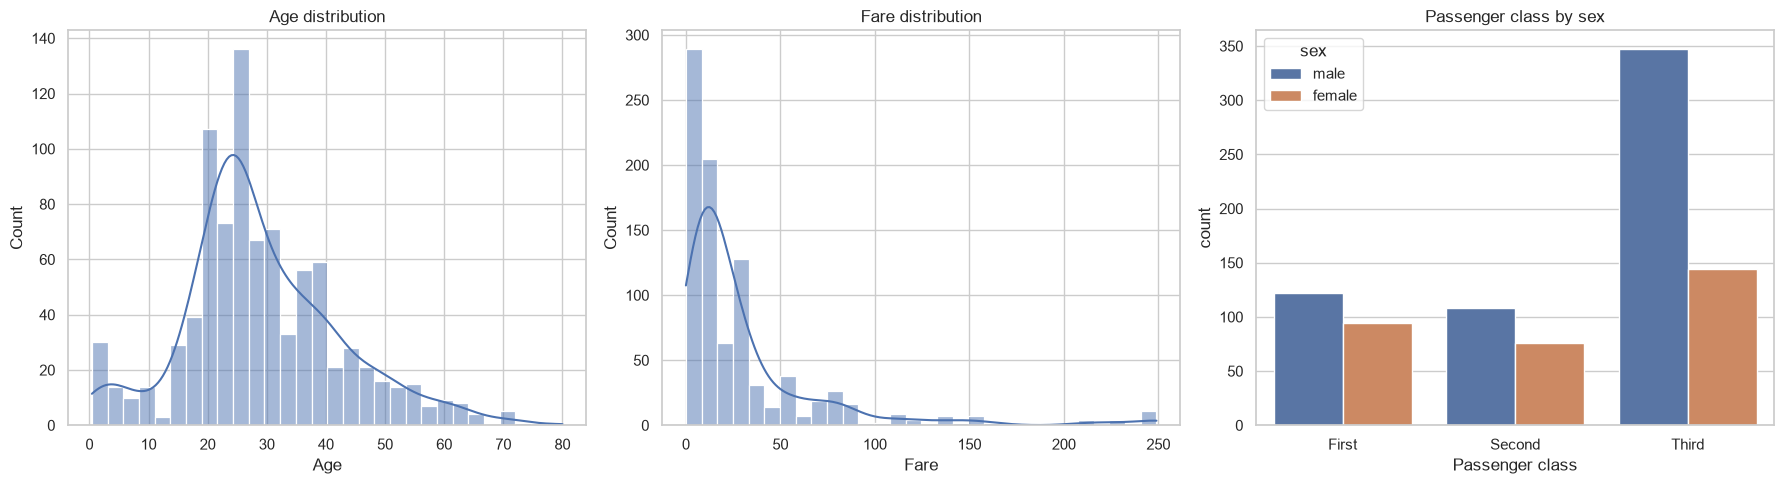

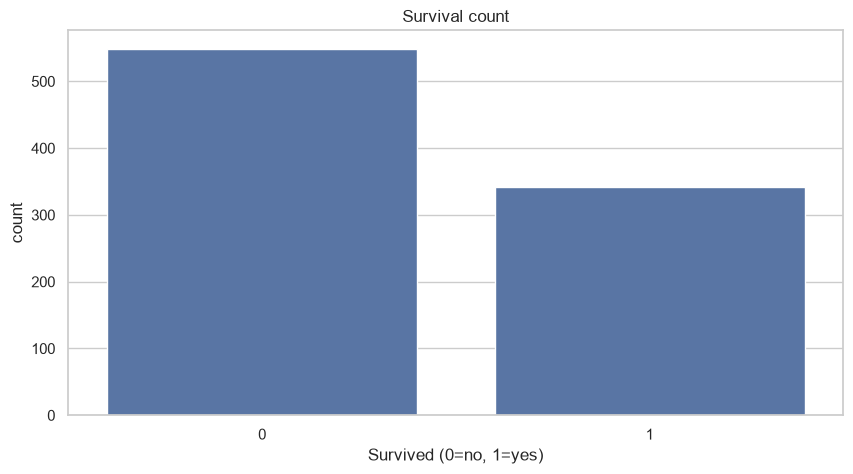

In [25]:
# Lightly cleaned copy for EDA (original scale; readable labels)
df_eda = df.copy()
df_eda['age'] = df_eda.groupby(['sex', 'pclass'])['age'].transform(lambda s: s.fillna(s.median()))
df_eda['embarked'] = df_eda['embarked'].fillna(df_eda['embarked'].mode()[0])
df_eda['fare'] = df_eda['fare'].clip(lower=df_eda['fare'].quantile(0.01), upper=df_eda['fare'].quantile(0.99))
df_eda['age_group'] = pd.cut(df_eda['age'], bins=[0, 12, 20, 30, 40, 50, 60, 80], labels=['0-11','12-19','20-29','30-39','40-49','50-59','60+'])

# Univariate analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df_eda['age'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Age distribution')
axes[0].set_xlabel('Age')

sns.histplot(df_eda['fare'], bins=30, kde=True, ax=axes[1])
axes[1].set_title('Fare distribution')
axes[1].set_xlabel('Fare')

sns.countplot(data=df_eda, x='class', hue='sex', ax=axes[2])
axes[2].set_title('Passenger class by sex')
axes[2].set_xlabel('Passenger class')
plt.tight_layout()
plt.show()

sns.countplot(data=df_eda, x='survived')
plt.title('Survival count')
plt.xlabel('Survived (0=no, 1=yes)')
plt.show()

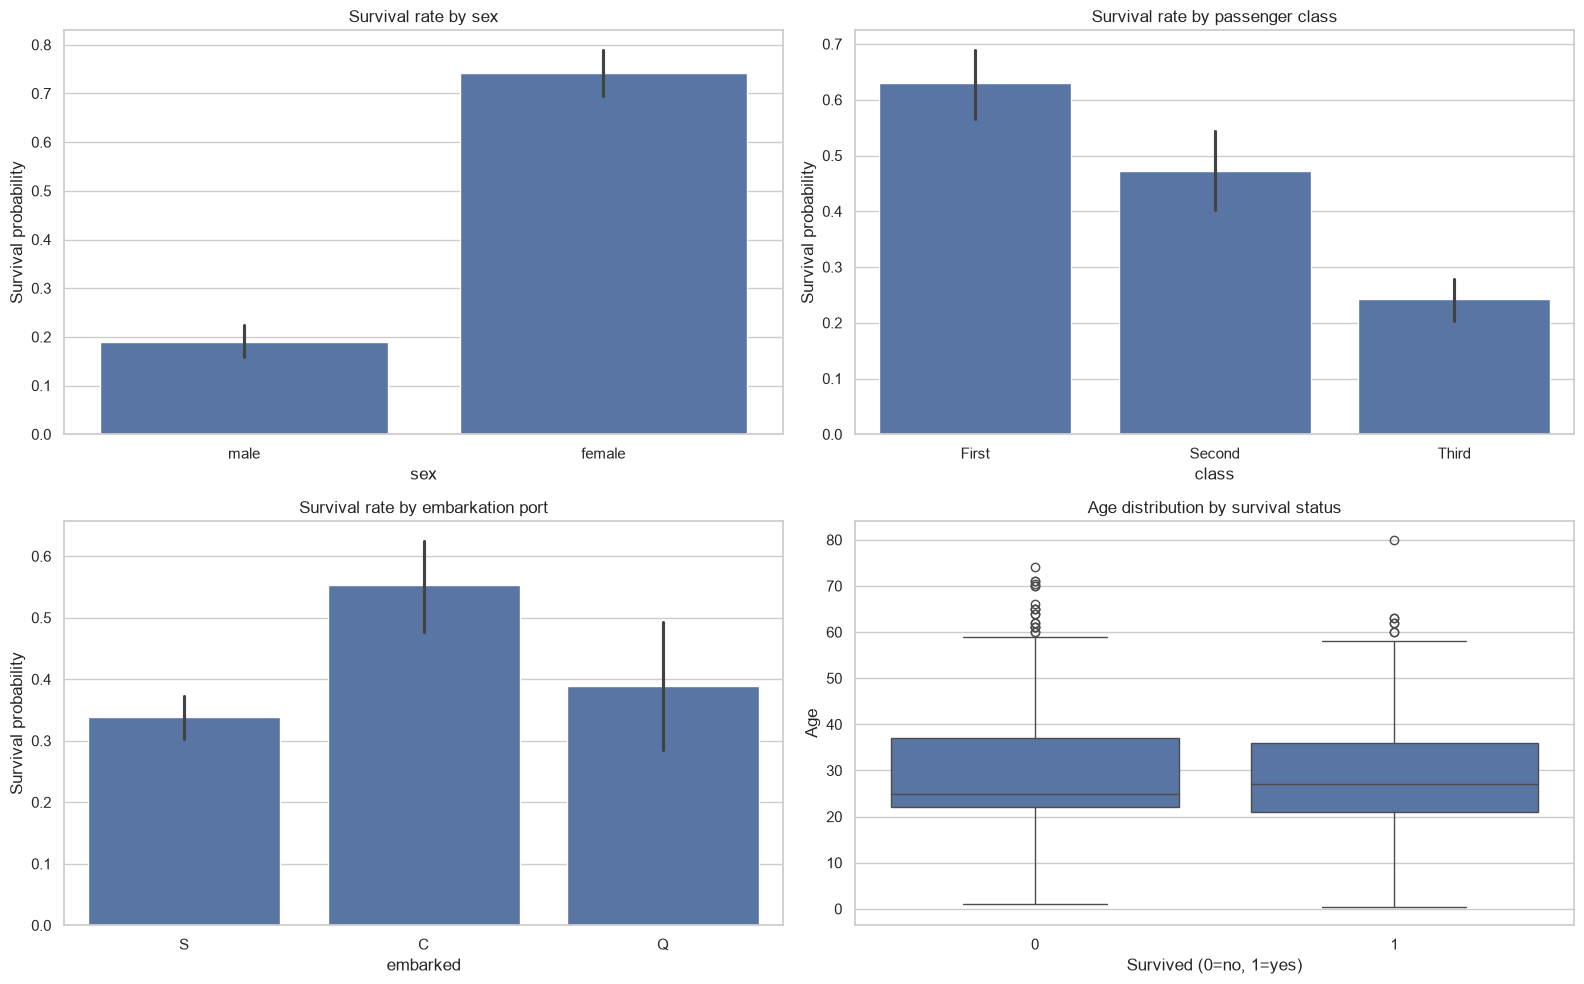

Survival rate by sex:
sex
female    0.742038
male      0.188908

Survival rate by class:
class
First     0.629630
Second    0.472826
Third     0.242363

Survival rate by embarkation port:
embarked
C    0.553571
Q    0.389610
S    0.339009


In [26]:
# Relationships with the target
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.barplot(data=df_eda, x='sex', y='survived', estimator='mean', ax=axes[0, 0])
axes[0, 0].set_title('Survival rate by sex')
axes[0, 0].set_ylabel('Survival probability')

sns.barplot(data=df_eda, x='class', y='survived', estimator='mean', ax=axes[0, 1])
axes[0, 1].set_title('Survival rate by passenger class')
axes[0, 1].set_ylabel('Survival probability')

sns.barplot(data=df_eda, x='embarked', y='survived', estimator='mean', ax=axes[1, 0])
axes[1, 0].set_title('Survival rate by embarkation port')
axes[1, 0].set_ylabel('Survival probability')

sns.boxplot(data=df_eda, x='survived', y='age', ax=axes[1, 1])
axes[1, 1].set_title('Age distribution by survival status')
axes[1, 1].set_xlabel('Survived (0=no, 1=yes)')
axes[1, 1].set_ylabel('Age')

plt.tight_layout()
plt.show()

print("Survival rate by sex:")
print(df_eda.groupby('sex')['survived'].mean().to_string())
print("\nSurvival rate by class:")
print(df_eda.groupby('class')['survived'].mean().to_string())
print("\nSurvival rate by embarkation port:")
print(df_eda.groupby('embarked')['survived'].mean().to_string())

Target proportions:
survived
0    0.616
1    0.384
Name: proportion, dtype: float64


C:\Users\mdmai\AppData\Local\Temp\ipykernel_29448\2165825226.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_counts.index, y=target_counts.values, palette=['#d95f02', '#1b9e77'])


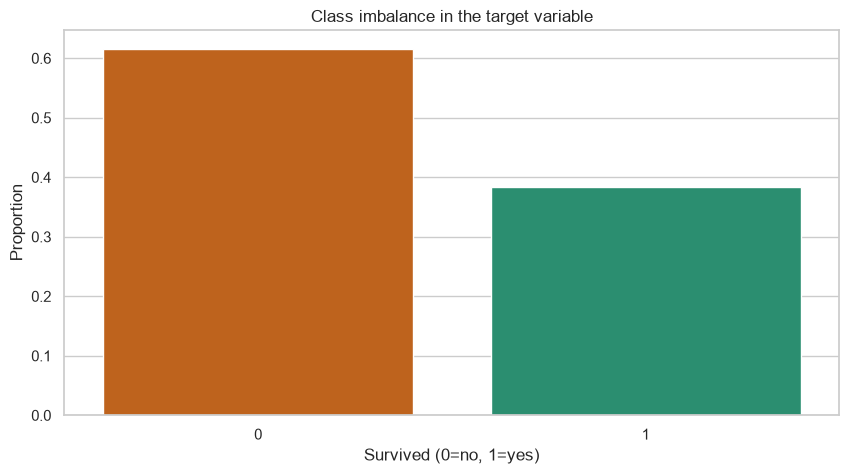

In [27]:
# Class imbalance
target_counts = df_eda['survived'].value_counts(normalize=True).sort_index()
print("Target proportions:")
print(target_counts.round(3))

sns.barplot(x=target_counts.index, y=target_counts.values, palette=['#d95f02', '#1b9e77'])
plt.title('Class imbalance in the target variable')
plt.xlabel('Survived (0=no, 1=yes)')
plt.ylabel('Proportion')
plt.show()

**Discussion of imbalance and its consequences for modelling:**
The survival outcome is somewhat imbalanced: roughly 38% of passengers survived and 62% did not. This imbalance is not extreme, but it matters because a naïve model could reach high accuracy simply by predicting the majority class. In practice, this means evaluation should rely on metrics beyond raw accuracy, such as precision, recall, F1 score, or ROC-AUC, and the model should be checked for sensitivity to the minority class.

### C.4 Key Insights

1. Women had a much higher survival rate than men, making `sex` one of the strongest signals in the data.
2. First-class passengers were more likely to survive than second- and third-class passengers, suggesting strong class-based survival differences.
3. Younger passengers and those in lower age groups showed different survival patterns than older passengers, though the relationship is not monotonic.
4. Fare and cabin access were associated with survival, consistent with the idea that wealth and access to safer areas mattered.
5. The target is moderately imbalanced, so performance should be evaluated with class-aware metrics.
6. Missing age values and a few noisy ticket prices should be treated carefully, because they can distort inference if not handled systematically.

## Part D – Short Written Report

This analysis asks a practical data-mining question: which passenger characteristics were associated with survival on the Titanic? The Titanic dataset is historically important and suitable for data-mining because it contains a mix of demographics, ticket information, and a binary outcome. The main finding is that survival was strongly linked to sex and passenger class, while age and fare also played non-trivial roles.

The cleaning process began with an assessment of missing values and data types. Age values were imputed using the median within sex and passenger class, which preserved key structure better than a single global median. Missing embarkation ports were filled with the most common value. Outliers in ticket fare were clipped, and categorical features were converted to dummy variables and standardized for modeling. This produced a reproducible pipeline that could be re-run from the raw dataset.

The exploratory analysis showed that women had substantially higher survival probabilities than men, first-class passengers had the best survival rates, and passengers who paid higher fares were more likely to survive. The outcome was moderately imbalanced, with around 38% survival, so model evaluation should not rely only on accuracy. Overall, the results suggest that survival was shaped by a mix of social privilege, gender, and accessibility to safer spaces on the ship.

For CS505, the critical reflection would highlight that the dataset reflects historical inequities and that social class and gender were not purely natural features; they were embedded in the social structure of the time. Any model based on this data must therefore be interpreted carefully and not applied as if it were an objective statement about fairness or causation.

## Extension – Required for CS505 only

### Extension A – Comparative imputation study
Three reasonable strategies for missing `age` values are: median imputation, median by sex and class, and regression-based imputation using other variables. A good comparison checks the distribution of age before and after imputation and tests how strongly the imputed variable relates to `survived`. In this assignment, median-by-sex-and-class is preferred because it respects the fact that age patterns differ by sex and social class and it is more robust than a single global median.

In [28]:
# CS505 – comparative imputation study for age
strategies = {}

# Strategy 1: global median
global_median = df['age'].median()
s1 = df['age'].fillna(global_median)
strategies['global_median'] = s1

# Strategy 2: median by sex and class
s2 = df.groupby(['sex', 'pclass'])['age'].transform(lambda s: s.fillna(s.median()))
strategies['median_by_sex_class'] = s2

# Strategy 3: simple regression-based estimate using related variables
df_reg = df[['age', 'sex', 'pclass', 'sibsp', 'parch', 'fare']].copy()
df_reg = pd.get_dummies(df_reg, columns=['sex', 'pclass'], drop_first=True)
train = df_reg.dropna(subset=['age']).copy()
target = train['age']
X = train.drop(columns=['age'])

# If sklearn is available, use a simple linear model. Otherwise skip modeling and use grouped mean as fallback.
try:
    from sklearn.linear_model import LinearRegression
    model = LinearRegression()
    model.fit(X, target)
    missing_idx = df_reg[df_reg['age'].isna()].index
    missing_X = df_reg.loc[missing_idx].drop(columns=['age'])
    s3 = df['age'].copy()
    s3.loc[missing_idx] = model.predict(missing_X)
    strategies['regression'] = s3
except Exception:
    strategies['regression'] = s2

for name, series in strategies.items():
    print(f'\n--- {name} ---')
    print(series.describe().round(2))
    print('Survival corrs:', round(series.corr(df['survived']), 3))


--- global_median ---
count    891.00
mean      29.36
std       13.02
min        0.42
25%       22.00
50%       28.00
75%       35.00
max       80.00
Name: age, dtype: float64
Survival corrs: -0.065

--- median_by_sex_class ---
count    891.00
mean      29.11
std       13.30
min        0.42
25%       21.50
50%       26.00
75%       36.00
max       80.00
Name: age, dtype: float64
Survival corrs: -0.06

--- regression ---
count    891.00
mean      29.36
std       13.67
min       -7.83
25%       21.64
50%       28.71
75%       36.00
max       80.00
Name: age, dtype: float64
Survival corrs: -0.053


**Extension B – Critical analysis and literature:**
One major limitation is historical bias: the dataset reflects social structures from 1912 and cannot be treated as a neutral sample of all passengers or all people. It also contains missingness that is not random, because age and cabin information are more likely to be missing for certain groups, which can distort relationships. A relevant peer-reviewed theme is fairness-aware analysis in historical data and missing-data imputation, where researchers stress that incomplete records and social stratification can produce biased conclusions if the preprocessing is not transparent. The preprocessing choices made here—grouped median imputation, feature reduction for weak columns, and careful outlier clipping—reduce unnecessary noise while keeping the analysis interpretable.